In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [4]:
df = pd.read_csv("CreditCard/creditcard.csv")

print(df.head())
print(df.shape)
print(df["Class"].value_counts())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [14]:
X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

print("Training shape:", X_train.shape)
print("Testing shap:", X_test.shape)


Training shape: (227845, 30)
Testing shap: (56962, 30)


In [15]:
X_train_normal = X_train[y_train == 0]

print("Normal training transactions:", X_train_normal.shape)

Normal training transactions: (227451, 30)


In [16]:
input_dim = X_train_normal.shape[1]

model = keras.Sequential([
    layers.Input(shape=(input_dim,)),

    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),

    layers.Dense(16, activation="relu"),
    layers.Dense(input_dim, activation="linear")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [18]:
history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

Epoch 1/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.7103 - mae: 0.5440 - val_loss: 0.4625 - val_mae: 0.4511
Epoch 2/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4271 - mae: 0.4304 - val_loss: 0.3747 - val_mae: 0.4105
Epoch 3/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3691 - mae: 0.3985 - val_loss: 0.3469 - val_mae: 0.3889
Epoch 4/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3477 - mae: 0.3818 - val_loss: 0.3318 - val_mae: 0.3757
Epoch 5/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3332 - mae: 0.3712 - val_loss: 0.3188 - val_mae: 0.3666
Epoch 6/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3186 - mae: 0.3627 - val_loss: 0.3041 - val_mae: 0.3586
Epoch 7/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3060 - mae: 0.3549 - val_loss: 0.2939 - val_mae: 0.3515
Epoch 8/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2965 - mae: 0.3481 - val_loss: 0.2868 - val_mae: 0.3461
Epoch 9/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - lo

In [19]:
reconstructions = model.predict(X_train_normal, verbose=0)

train_errors = np.mean(
    np.square(X_train_normal - reconstructions),
    axis=1
)

threshold = np.percentile(train_errors, 99)

print("Fraud Detection Threshold:", threshold)

Fraud Detection Threshold: 1.4286649


In [20]:
test_reconstructions = model.predict(X_test, verbose=0)

test_errors = np.mean(
    np.square(X_test - test_reconstructions),
    axis=1
)

y_pred = (test_errors > threshold).astype(int)

In [21]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[56264   600]
 [   13    85]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.87      0.22        98

    accuracy                           0.99     56962
   macro avg       0.56      0.93      0.61     56962
weighted avg       1.00      0.99      0.99     56962



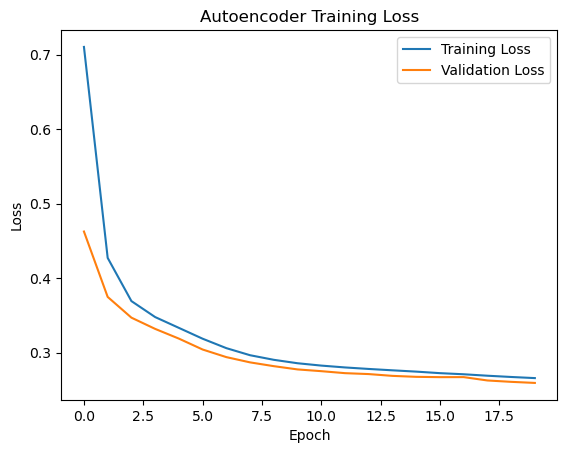

In [22]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

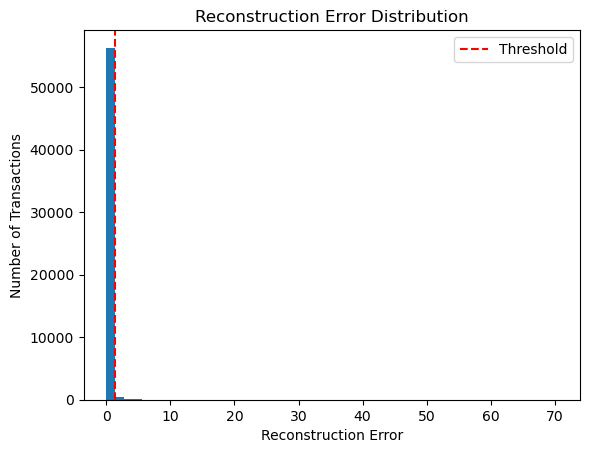

In [23]:
plt.hist(test_errors, bins=50)
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")

plt.title("Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.legend()
plt.show()